In [1]:
# Import necessary libraries
import os
import glob
import json

import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches

%matplotlib widget


In [2]:
def get_boxes(label_paths, video_names, name): 
    tmp_label_pths = label_paths[np.in1d(video_names, name)]
    boxes = []
    for pth in tmp_label_pths:
        tmp_boxes= []
        with open(pth, "rt") as f:
            for line in f.readlines():
                _, x_c, y_c, w, h, _, _ = [float(i) for i in line.split()]
                tmp_boxes.append([x_c, y_c, w, h])
        boxes.append(tmp_boxes)
    
    return boxes

In [3]:
def distance_to_frame_boundaries(boxes):
    # Calculate the left, right, top, and bottom distances
    left_distances = boxes[:, 0] - boxes[:, 2] / 2
    right_distances = 1 - (boxes[:, 0] + boxes[:, 2] / 2)
    top_distances = boxes[:, 1] - boxes[:, 3] / 2
    bottom_distances = 1 - (boxes[:, 1] + boxes[:, 3] / 2)
    
    # Stack the distances into a single array
    distances = np.stack((left_distances, right_distances, top_distances, bottom_distances), axis=1)
    
    # Find the minimum distance for each bounding box
    min_distances = np.min(distances, axis=1)
    
    return min_distances

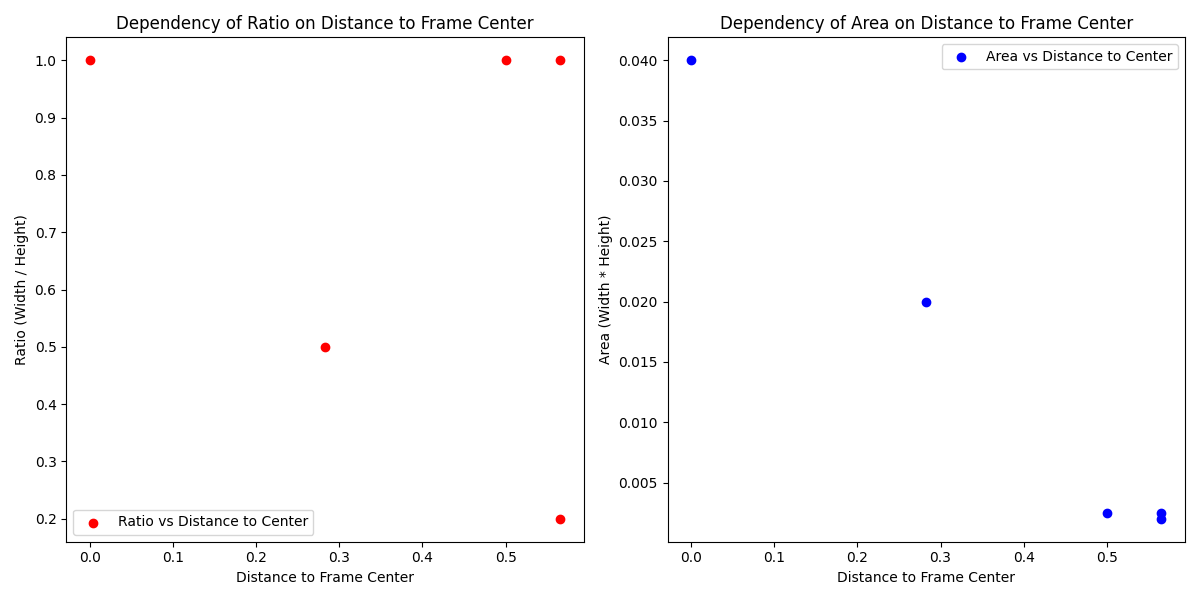

Correlation between Ratio and Distance to Center: -0.26608598899264047
Correlation between Area and Distance to Center: -0.9944591704972591


In [4]:
def calculate_ratio_and_area(boxes):
    """
    Calculate the ratio and area for each bounding box.

    Parameters:
    - boxes: A numpy array of bounding boxes in YOLO format [x_center, y_center, w, h].

    Returns:
    - ratios: A numpy array of ratios (width/height) for each bounding box.
    - areas: A numpy array of areas (width * height) for each bounding box.
    """
    widths = boxes[:, 2]
    heights = boxes[:, 3]
    ratios = widths / heights
    areas = widths * heights
    return ratios, areas

def calculate_distance_to_center(boxes):
    """
    Calculate the distance to the frame center for each bounding box.

    Parameters:
    - boxes: A numpy array of bounding boxes in YOLO format [x_center, y_center, w, h].

    Returns:
    - distances: A numpy array of distances to the frame center for each bounding box.
    """
    x_centers = boxes[:, 0]
    y_centers = boxes[:, 1]
    distances = np.sqrt((x_centers - 0.5) ** 2 + (y_centers - 0.5) ** 2)
    return distances

def analyze_dependency(boxes):
    """
    Analyze the dependency between bounding box ratio/area and its distance to the frame center.

    Parameters:
    - boxes: A numpy array of bounding boxes in YOLO format [x_center, y_center, w, h].
    """
    distances = calculate_distance_to_center(boxes)
    ratios, areas = calculate_ratio_and_area(boxes)

    # Scatter plot for ratio vs distance to center
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.scatter(distances, ratios, c='r', label='Ratio vs Distance to Center')
    plt.xlabel('Distance to Frame Center')
    plt.ylabel('Ratio (Width / Height)')
    plt.legend()
    plt.title('Dependency of Ratio on Distance to Frame Center')

    # Scatter plot for area vs distance to center
    plt.subplot(1, 2, 2)
    plt.scatter(distances, areas, c='b', label='Area vs Distance to Center')
    plt.xlabel('Distance to Frame Center')
    plt.ylabel('Area (Width * Height)')
    plt.legend()
    plt.title('Dependency of Area on Distance to Frame Center')

    plt.tight_layout()
    plt.show()

    # Calculate correlation coefficients
    corr_ratio_distance = np.corrcoef(distances, ratios)[0, 1]
    corr_area_distance = np.corrcoef(distances, areas)[0, 1]

    print(f"Correlation between Ratio and Distance to Center: {corr_ratio_distance}")
    print(f"Correlation between Area and Distance to Center: {corr_area_distance}")

# Example usage
boxes = np.array([
    [0.1, 0.1, 0.05, 0.05],  # Likely truncated
    [0.9, 0.8, 0.05, 0.05],  # Likely truncated
    [0.5, 0.5, 0.2, 0.2],    # Likely valid
    [0.3, 0.7, 0.1, 0.2],    # Likely valid
    [0.9, 0.9, 0.02, 0.1]    # Likely truncated
])

analyze_dependency(boxes)

In [5]:
def filter_truncated_boxes(boxes, aspect_ratio_range=(0.5, 2.0), min_area_ratio=0.01, margin=0.1, max_distance=0.5):
    """
    Filter out truncated bounding boxes based on aspect ratio, size, position, and distance to center.

    Parameters:
    - boxes: A numpy array of bounding boxes in YOLO format [x_center, y_center, w, h].
    - aspect_ratio_range: A tuple (min_aspect_ratio, max_aspect_ratio) to filter by aspect ratio.
    - min_area_ratio: Minimum area ratio threshold to filter by size, relative to the largest bounding box.
    - margin: Margin around the edges of the frame to filter by position.
    - max_distance: Maximum distance from the center to filter by distance.

    Returns:
    - filtered_boxes: A numpy array of filtered bounding boxes.
    """
    x_centers = boxes[:, 0]
    y_centers = boxes[:, 1]
    widths = boxes[:, 2]
    heights = boxes[:, 3]

    # Calculate aspect ratios and areas
    aspect_ratios = widths / heights
    areas = widths * heights

    # Normalize areas relative to the largest bounding box in the frame
    max_area = np.max(areas)
    normalized_areas = areas / max_area

    # Calculate distances to the frame center
    distances = np.sqrt((x_centers - 0.5) ** 2 + (y_centers - 0.5) ** 2)

    # Filter by aspect ratio
    aspect_ratio_filter = (aspect_ratios >= aspect_ratio_range[0]) & (aspect_ratios <= aspect_ratio_range[1])

    # Filter by normalized area
    area_filter = normalized_areas >= min_area_ratio

    # Filter by position (margin)
    left_margin_filter = (x_centers - widths / 2) >= margin
    right_margin_filter = (x_centers + widths / 2) <= (1 - margin)
    top_margin_filter = (y_centers - heights / 2) >= margin
    bottom_margin_filter = (y_centers + heights / 2) <= (1 - margin)
    position_filter = left_margin_filter & right_margin_filter & top_margin_filter & bottom_margin_filter

    # Filter by distance to center
    distance_filter = distances <= max_distance

    # Combine all filters
    combined_filter = aspect_ratio_filter & area_filter & position_filter & distance_filter

    # Apply the filter to the bounding boxes
    filtered_boxes = boxes[combined_filter]

    return filtered_boxes

# Example usage
boxes = np.array([
    [0.1, 0.1, 0.05, 0.05],  # Likely truncated
    [0.9, 0.8, 0.05, 0.05],  # Likely truncated
    [0.5, 0.5, 0.2, 0.2],    # Likely valid
    [0.3, 0.7, 0.1, 0.2],    # Likely valid
    [0.9, 0.9, 0.02, 0.1]    # Likely truncated
])

filtered_boxes = filter_truncated_boxes(boxes)
print(filtered_boxes)

[[0.5 0.5 0.2 0.2]
 [0.3 0.7 0.1 0.2]]


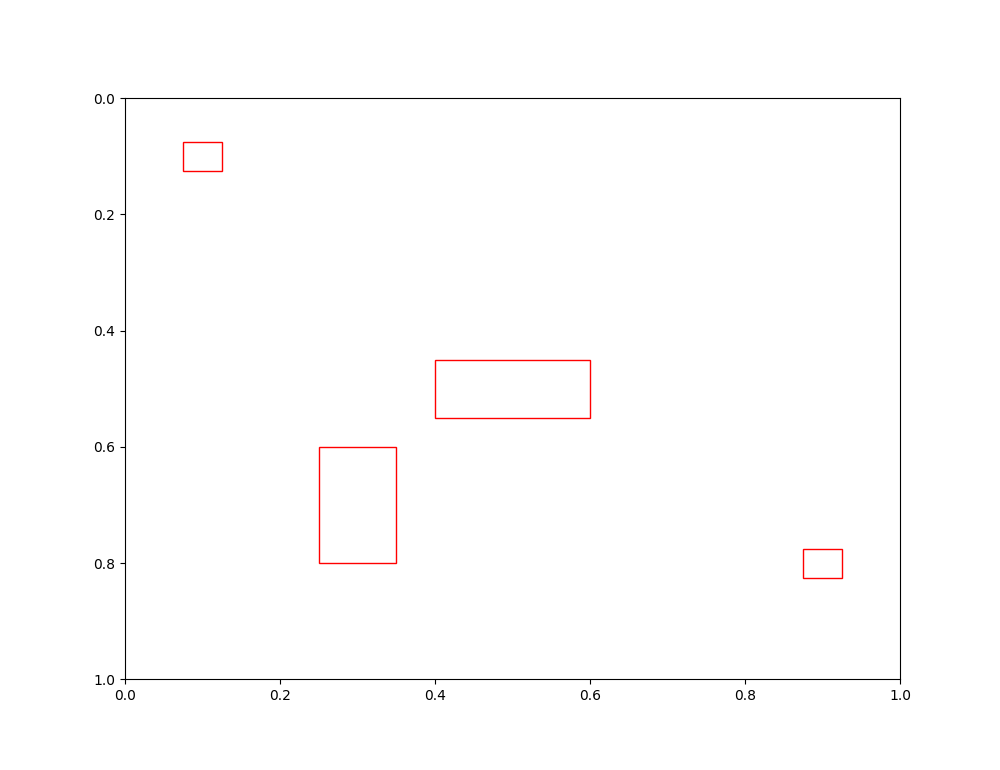

In [6]:
def draw_bounding_boxes_with_info(boxes, edge_threshold=0.01):
    """
    Draw bounding boxes and display additional information on hover.

    Parameters:
    - boxes: A numpy array of bounding boxes in YOLO format [x_center, y_center, w, h].
    """
    fig, ax = plt.subplots(1, figsize=(10, 7.7))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect(3/4)  # Set the aspect ratio of the plot to be equal
    ax.invert_yaxis()  # Invert the y-axis to match OpenCV's coordinate system

    # Calculate additional information for each bounding box
    widths = boxes[:, 2]
    heights = boxes[:, 3]
    areas = widths * heights
    max_area = np.max(areas)
    normalized_areas = areas / max_area

    # # Calculate the margin sizes
    # left_margins = boxes[:, 0] - widths / 2  # Distance from left side of the box to the left edge of the frame
    # right_margins = 1 - (boxes[:, 0] + widths / 2)  # Distance from right side of the box to the right edge of the frame
    # top_margins = boxes[:, 1] - heights / 2  # Distance from top side of the box to the top edge of the frame
    # bottom_margins = 1 - (boxes[:, 1] + heights / 2)  # Distance from bottom side of the box to the bottom edge of the frame
    # Calculate the margin sizes
    left_margins = boxes[:, 0] + widths / 2  # Distance from right side of the box to the left edge of the frame
    right_margins = 1 - (boxes[:, 0] - widths / 2)  # Distance from left side of the box to the right edge of the frame
    top_margins = boxes[:, 1] + heights / 2  # Distance from bottom side of the box to the top edge of the frame
    bottom_margins = 1 - (boxes[:, 1] - heights / 2)  # Distance from top side of the box to the bottom edge of the frame

    aspect_ratios = widths / heights

    # Draw bounding boxes and set up interactive features
    for i, box in enumerate(boxes):
        x_center, y_center, w, h = box
        x = x_center - w / 2
        y = y_center - h / 2
        rect = patches.Rectangle((x, y), w, h, linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(rect)

        # Determine the position of the annotation
        if x_center + 0.1 > 1:
            annotation_x = x_center - 0.1
        else:
            annotation_x = x_center + 0.1

        # Add a text annotation for interactivity
        annotation = ax.annotate(
            f"Normalized Area: {normalized_areas[i]:.2f}\n"
            f"Left Margin: {left_margins[i]:.2f}\n"
            f"Right Margin: {right_margins[i]:.2f}\n"
            f"Top Margin: {top_margins[i]:.2f}\n"
            f"Bottom Margin: {bottom_margins[i]:.2f}\n"
            f"Aspect Ratio: {aspect_ratios[i]:.2f}",
            xy=(x_center, y_center),
            xytext=(annotation_x, y_center + 0.05),
            textcoords='data',
            bbox=dict(boxstyle="round,pad=0.3", edgecolor='black', facecolor='white'),
            fontsize=8,
            color='black',
            visible=False
        )

        # Store the annotation in the rectangle object for easy access
        rect.annotation = annotation

    def on_hover(event):
        # Check if the mouse is within the plot area
        if event.xdata is None or event.ydata is None:
            for rect in ax.patches:
                rect.annotation.set_visible(False)
            fig.canvas.draw_idle()
            return

        # Check if the mouse is near the edge of a rectangle
        for rect in ax.patches:
            x0, y0 = rect.get_xy()
            x1, y1 = x0 + rect.get_width(), y0 + rect.get_height()
            contains = (
                (abs(event.xdata - x0) < edge_threshold or abs(event.xdata - x1) < edge_threshold) and y0 <= event.ydata <= y1 or
                (abs(event.ydata - y0) < edge_threshold or abs(event.ydata - y1) < edge_threshold) and x0 <= event.xdata <= x1
            )
            if contains:
                rect.annotation.set_visible(True)
            else:
                rect.annotation.set_visible(False)
        fig.canvas.draw_idle()

    # Connect the hover event to the on_hover function
    fig.canvas.mpl_connect('motion_notify_event', on_hover)

    plt.show()

# Example usage
# Define bounding boxes in YOLO format
boxes = np.array([
    [0.1, 0.1, 0.05, 0.05],
    [0.9, 0.8, 0.05, 0.05],
    [0.5, 0.5, 0.2, 0.1],
    [0.3, 0.7, 0.1, 0.2]
])

# Enable the ipympl backend
%matplotlib widget

draw_bounding_boxes_with_info(boxes)

In [12]:
BASE_PTH = "/home/klymy/data/people_detection/filtered_v2_10_sec"
SUBSET = "val"
IMGS_PTH = os.path.join(BASE_PTH, "images", SUBSET)
LABELS_PTH = os.path.join(BASE_PTH, "labels", SUBSET)

img_paths = np.array(sorted(glob.glob(os.path.join(IMGS_PTH, "*"))))
label_paths = np.array(sorted(glob.glob(os.path.join(LABELS_PTH, "*"))))

video_names = [os.path.basename(i)[:-10] for i in img_paths]
uvideo_names, inverse_mapping = np.unique(video_names, return_inverse=True)

len(uvideo_names), len(video_names)

(810, 14910)

No such comm: d1b51c8f4a414a408178355e04917a80


(55, 4)


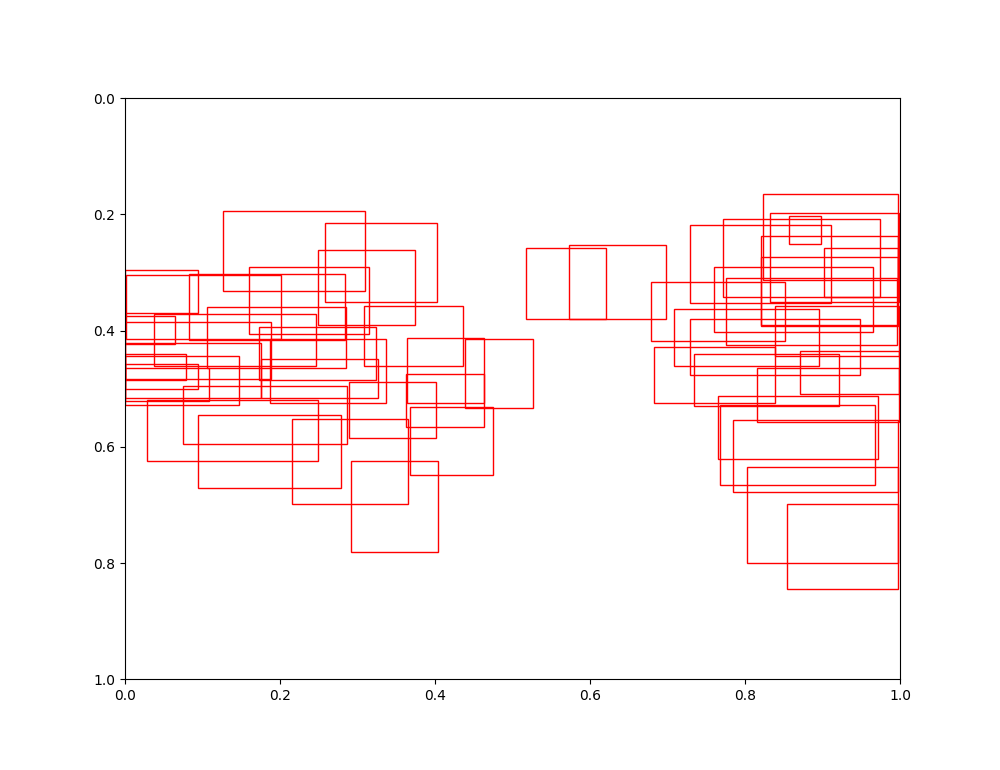

In [16]:
idx = 701
uvideo_name = uvideo_names[idx]

boxes = get_boxes(label_paths, video_names, uvideo_name)
boxes = np.concatenate(boxes)
print(boxes.shape)

draw_bounding_boxes_with_info(boxes)